# Retail Sales Forecasting using Machine Learning

In [222]:
import pandas as pd

In [223]:
import pandas as pd

df = pd.read_excel(r"C:\Users\adiya\OneDrive\Desktop\data-Science-week2\dataset\retail.xlsx")

In [224]:
df

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France


In [225]:
df

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France


# 1. Understanding About Data

In [226]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [227]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


## Checking for MIssing Values and duplicates

In [228]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [229]:
df.duplicated().sum()

np.int64(5268)

In [230]:
df.nunique()

InvoiceNo      25900
StockCode       4070
Description     4223
Quantity         722
InvoiceDate    23260
UnitPrice       1630
CustomerID      4372
Country           38
dtype: int64

In [231]:
df['Country'].unique()

array(['United Kingdom', 'France', 'Australia', 'Netherlands', 'Germany',
       'Norway', 'EIRE', 'Switzerland', 'Spain', 'Poland', 'Portugal',
       'Italy', 'Belgium', 'Lithuania', 'Japan', 'Iceland',
       'Channel Islands', 'Denmark', 'Cyprus', 'Sweden', 'Austria',
       'Israel', 'Finland', 'Bahrain', 'Greece', 'Hong Kong', 'Singapore',
       'Lebanon', 'United Arab Emirates', 'Saudi Arabia',
       'Czech Republic', 'Canada', 'Unspecified', 'Brazil', 'USA',
       'European Community', 'Malta', 'RSA'], dtype=object)

In [232]:
df['Description'].unique()

array(['WHITE HANGING HEART T-LIGHT HOLDER', 'WHITE METAL LANTERN',
       'CREAM CUPID HEARTS COAT HANGER', ..., 'lost',
       'CREAM HANGING HEART T-LIGHT HOLDER',
       'PAPER CRAFT , LITTLE BIRDIE'], shape=(4224,), dtype=object)

# Task 1 . Data Analysis

## Missing value analysis

In [233]:
missing = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': df.isnull().mean() * 100
})

missing

,Missing_Count,Missing_Percentage
InvoiceNo,0,0.000000
StockCode,0,0.000000
Description,1454,0.268311
Quantity,0,0.000000
InvoiceDate,0,0.000000
UnitPrice,0,0.000000
CustomerID,135080,24.926694
Country,0,0.000000


In [234]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_style('whitegrid')

## Duplicate analysis

In [235]:
print("Total duplicate rows:", df.duplicated().sum())

print("Duplicate InvoiceNo:", df['InvoiceNo'].duplicated().sum())

Total duplicate rows: 5268
Duplicate InvoiceNo: 516009


## Analyze Quantity and UnitPrice

In [236]:
print("=" * 60)
print("          QUANTITY AND UNIT PRICE ANALYSIS")
print("=" * 60)

# Quantity Analysis
print("\n1. QUANTITY SUMMARY")
print("-" * 40)
print(df['Quantity'].describe().to_string())

# Unit Price Analysis
print("\n2. UNIT PRICE SUMMARY")
print("-" * 40)
print(df['UnitPrice'].describe().to_string())

# Negative and Zero Value Analysis
print("\n3. DATA QUALITY CHECK")
print("-" * 40)

print(f"Negative Quantity Records : {(df['Quantity'] < 0).sum():,}")
print(f"Zero Quantity Records     : {(df['Quantity'] == 0).sum():,}")
print(f"Negative UnitPrice Records: {(df['UnitPrice'] < 0).sum():,}")
print(f"Zero UnitPrice Records    : {(df['UnitPrice'] == 0).sum():,}")

print("=" * 60)

          QUANTITY AND UNIT PRICE ANALYSIS

1. QUANTITY SUMMARY
----------------------------------------
count    541909.000000
mean          9.552250
std         218.081158
min      -80995.000000
25%           1.000000
50%           3.000000
75%          10.000000
max       80995.000000

2. UNIT PRICE SUMMARY
----------------------------------------
count    541909.000000
mean          4.611114
std          96.759853
min      -11062.060000
25%           1.250000
50%           2.080000
75%           4.130000
max       38970.000000

3. DATA QUALITY CHECK
----------------------------------------
Negative Quantity Records : 10,624
Zero Quantity Records     : 0
Negative UnitPrice Records: 2
Zero UnitPrice Records    : 2,515


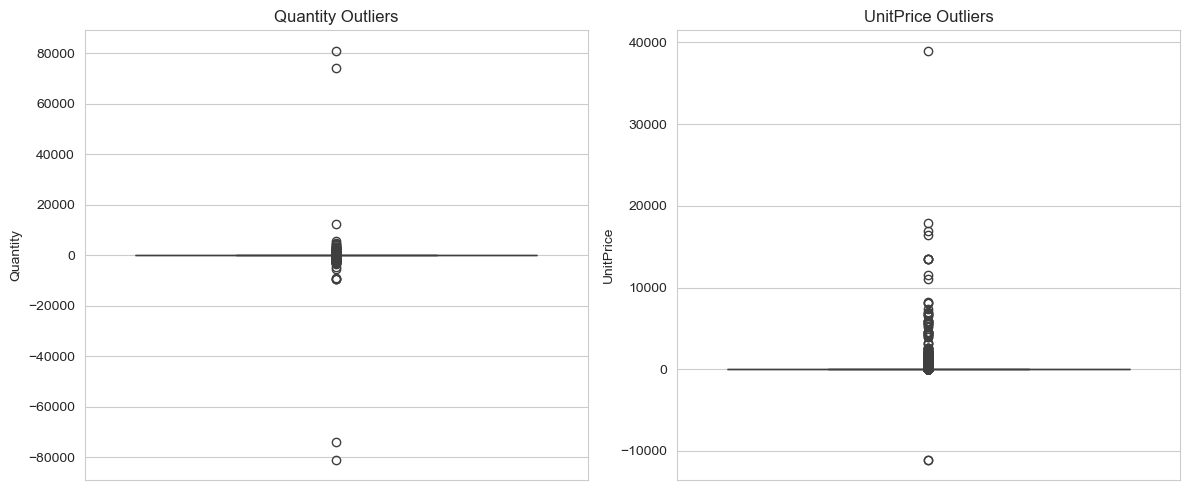

In [237]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
sns.boxplot(y=df['Quantity'])
plt.title('Quantity Outliers')

plt.subplot(1,2,2)
sns.boxplot(y=df['UnitPrice'])
plt.title('UnitPrice Outliers')

plt.tight_layout()
plt.show()

## Analyze sales by country

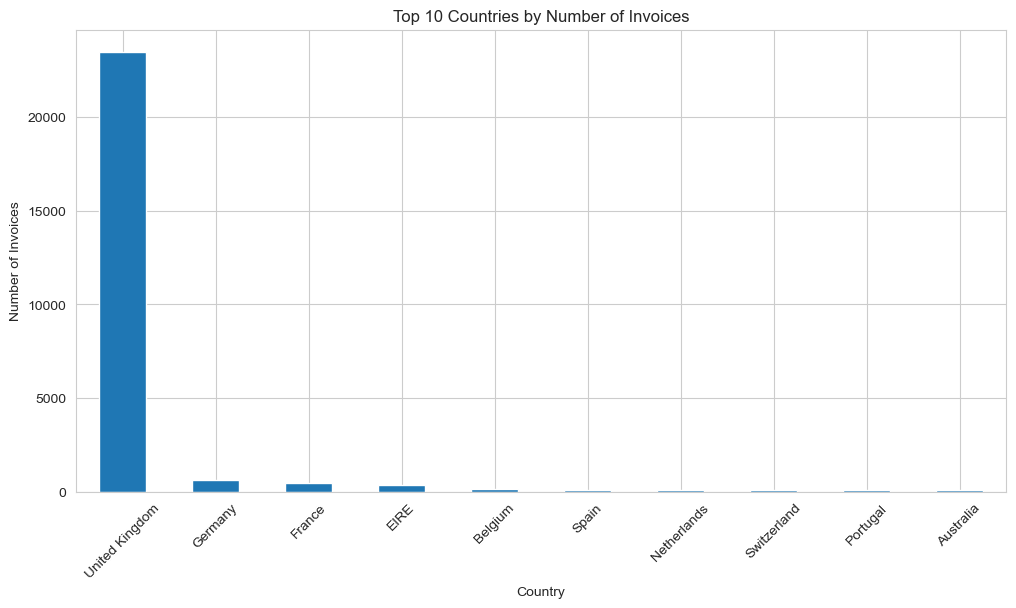

In [238]:
country_orders = df.groupby('Country')['InvoiceNo'].nunique().sort_values(ascending=False)

plt.figure(figsize=(12,6))
country_orders.head(10).plot(kind='bar')
plt.title('Top 10 Countries by Number of Invoices')
plt.xlabel('Country')
plt.ylabel('Number of Invoices')
plt.xticks(rotation=45)
plt.show()

## Analyze top-selling products

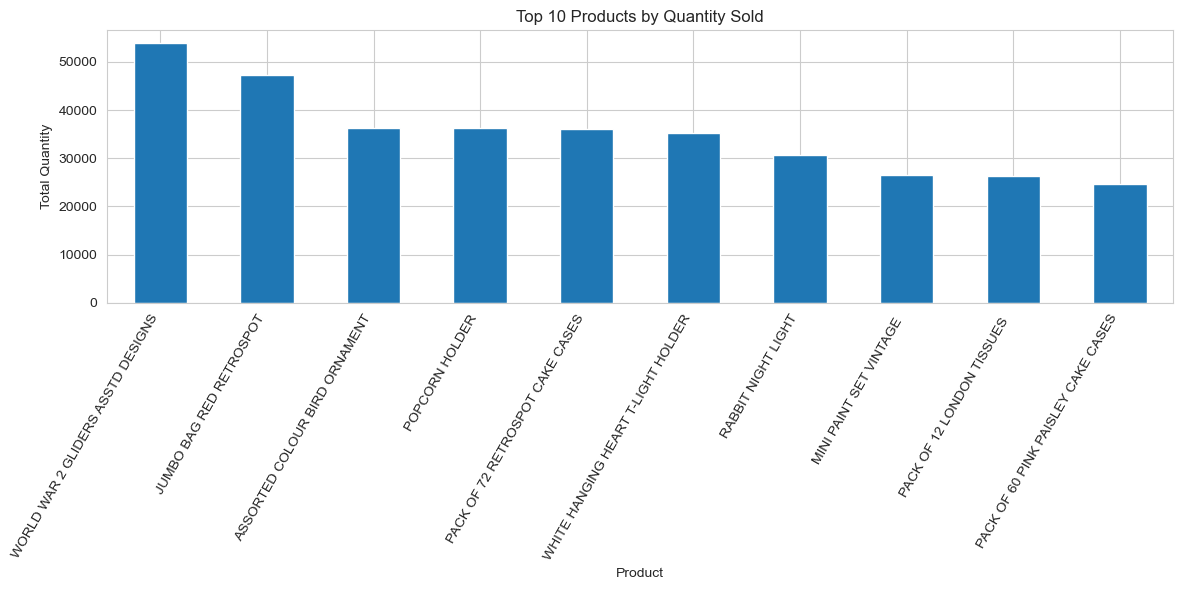

In [239]:
top_products = (
    df.groupby('Description')['Quantity']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12,6))
top_products.plot(kind='bar')
plt.title('Top 10 Products by Quantity Sold')
plt.xlabel('Product')
plt.ylabel('Total Quantity')
plt.xticks(rotation=60, ha='right')
plt.tight_layout()
plt.show()

#  Task 2. Data Preposecingand EDA

## Convert InvoiceDate into datetime

In [240]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

print(df['InvoiceDate'].dtype)

datetime64[ns]


### filling Missing values

In [241]:
df['Description'] = df.groupby('StockCode')['Description'].transform(
    lambda x: x.fillna(
        x.mode().iloc[0] if not x.mode().empty else 'Unknown'
    )
)

I used this code to fill missing values in the Description column. First, I grouped products using StockCode. Then, I found the most repeated description for each product and used it to fill missing values. If a product had no description available, I filled it with 'Unknown

In [242]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Why not fill missing CustomerID?
1. Mean/Median: Not suitable because CustomerID is an identifier, not a numerical measurement.
2. Mode: Filling with the most common CustomerID would assign the wrong customer.
3. Unknown: We can use this for display, but it doesn't recover the actual customer identity.
4. Drop rows: We may lose useful sales information.

## Handling Duplicated

In [243]:
# Count exact duplicate rows
print("Total Exact Duplicate Rows:", df.duplicated().sum())

Total Exact Duplicate Rows: 5268


In [244]:
# Display all rows involved in exact duplication
exact_duplicates = df[df.duplicated(keep=False)]

display(exact_duplicates.head(20))

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
548,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom


In [245]:
# Count repeated invoice numbers
invoice_counts = df['InvoiceNo'].value_counts()

repeated_invoices = invoice_counts[invoice_counts > 1]

print("Total Unique Invoices:", df['InvoiceNo'].nunique())
print("Repeated Invoice Numbers:", len(repeated_invoices))

Total Unique Invoices: 25900
Repeated Invoice Numbers: 20059


In [246]:
# Select one invoice with multiple records
sample_invoice = repeated_invoices.index[0]

# Display its records
invoice_data = df[df['InvoiceNo'] == sample_invoice]

display(invoice_data)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
430237,573585,11001,ASSTD DESIGN RACING CAR PEN,2,2011-10-31 14:41:00,3.29,NaN,United Kingdom
430238,573585,15036,ASSORTED COLOURS SILK FAN,15,2011-10-31 14:41:00,1.63,NaN,United Kingdom
430239,573585,15039,SANDALWOOD FAN,15,2011-10-31 14:41:00,1.63,NaN,United Kingdom
430240,573585,15056BL,EDWARDIAN PARASOL BLACK,1,2011-10-31 14:41:00,12.46,NaN,United Kingdom
430241,573585,15056N,EDWARDIAN PARASOL NATURAL,1,2011-10-31 14:41:00,12.46,NaN,United Kingdom
...,...,...,...,...,...,...,...,...
431346,573585,90209C,PINK ENAMEL+GLASS HAIR COMB,3,2011-10-31 14:41:00,2.07,NaN,United Kingdom
431347,573585,90214S,"LETTER ""S"" BLING KEY RING",1,2011-10-31 14:41:00,0.83,NaN,United Kingdom
431348,573585,DOT,DOTCOM POSTAGE,1,2011-10-31 14:41:00,2019.05,NaN,United Kingdom
431349,573585,gift_0001_20,Dotcomgiftshop Gift Voucher £20.00,1,2011-10-31 14:41:00,16.67,NaN,United Kingdom


In [247]:
# Check repeated product lines within an invoice
duplicate_lines = df[
    df.duplicated(
        subset=['InvoiceNo', 'StockCode'],
        keep=False
    )
]

print("Repeated Invoice-Product Combinations:",
      len(duplicate_lines))

display(duplicate_lines.head(20))

Repeated Invoice-Product Combinations: 20378


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
113,536381,71270,PHOTO CLIP LINE,1,2010-12-01 09:41:00,1.25,15311.0,United Kingdom
125,536381,71270,PHOTO CLIP LINE,3,2010-12-01 09:41:00,1.25,15311.0,United Kingdom
483,536409,90199C,5 STRAND GLASS NECKLACE CRYSTAL,3,2010-12-01 11:45:00,6.35,17908.0,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
491,536409,85116,BLACK CANDELABRA T-LIGHT HOLDER,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
498,536409,90199C,5 STRAND GLASS NECKLACE CRYSTAL,1,2010-12-01 11:45:00,6.35,17908.0,United Kingdom
502,536409,85116,BLACK CANDELABRA T-LIGHT HOLDER,5,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom


Invoice 536381: Not an exact duplicate because quantities differ.



Invoice 536409: Multiple entries for the same products. They may be separate transaction lines.



Invoice 536412: The two records look like potential duplicates because their details match.

In [248]:
print("Before:", df.shape)

df = df.drop_duplicates()

print("After:", df.shape)

Before: (541909, 8)
After: (536641, 8)


In [249]:
df.duplicated().sum()

np.int64(0)

## 5. Duplicate Analysis – Findings and Recommendations

| Finding | What to Do | Reason |
|---|---|---|
| Repeated InvoiceNo | Keep | One invoice can contain multiple products. |
| Repeated StockCode | Keep | The same product can be purchased multiple times. |
| Same InvoiceNo + Different StockCode | Keep | Different products can belong to the same invoice. |
| Same InvoiceNo + Same StockCode + Different Quantity | Investigate; do not delete | The same product may appear in multiple transaction lines with different quantities. |
| Exact Duplicate Rows | Investigate and consider removing | Completely identical records may indicate duplicate entries. |
| Missing CustomerID | Keep | Customer information is unavailable, but the sales transaction may still be valid. |

### Conclusion

Repeated InvoiceNo and StockCode values are normal in retail transaction data. They do not automatically indicate duplicate records.

I checked repeated InvoiceNo and InvoiceNo + StockCode combinations to identify repeated transactions and product entries. Since repeated product entries may have different quantities, I will investigate them before removing any records.

## 6. Understanding Duplicate Counts

| Metric | Result | Meaning |
|---|---:|---|
| Total Unique Invoices | 25,900 | Number of distinct invoice numbers. |
| Repeated Invoice Numbers | 20,059 | Needs verification to determine whether this represents repeated invoice groups or rows belonging to repeated invoices. |
| Repeated Invoice-Product Combinations | 20,378 | Needs verification to determine whether this represents repeated combinations or duplicate rows. |

**Important Note:**

- Repeated invoice numbers do not necessarily mean duplicate data.
- Repeated StockCode values do not necessarily mean duplicate data.
- Repeated InvoiceNo + StockCode combinations require further investigation.
- Exact duplicate rows should be checked before removal.

**Final Decision:** Do not remove records only because InvoiceNo or StockCode is repeated. Remove only verified duplicate records when appropriate.

## Investigate cancellations and returns

In [250]:
df['InvoiceNo'] = df['InvoiceNo'].astype(str)

df['IsCancelled'] = df['InvoiceNo'].str.startswith('C')

print(df['IsCancelled'].value_counts())

IsCancelled
False    527390
True       9251
Name: count, dtype: int64


C:\Users\adiya\AppData\Local\Temp\ipykernel_24228\2782385267.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['InvoiceNo'] = df['InvoiceNo'].astype(str)
C:\Users\adiya\AppData\Local\Temp\ipykernel_24228\2782385267.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['IsCancelled'] = df['InvoiceNo'].str.startswith('C')


"I investigated cancellations to identify transactions that were not successful sales. My dataset contains 9,251 cancelled records and 527,390 normal records. I excluded cancelled transactions from successful sales and revenue analysis, but retained them separately to understand cancellation patterns

In [251]:
# Check cancelled transactions
cancelled_data = df[df['IsCancelled'] == True]

display(cancelled_data.head(10))

# Check their quantity
print(cancelled_data['Quantity'].describe())

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCancelled
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom,True
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom,True
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom,True
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom,True
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom,True
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom,True
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom,True
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom,True
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom,True
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom,True


count     9251.000000
mean       -29.787050
std       1147.997592
min     -80995.000000
25%         -6.000000
50%         -2.000000
75%         -1.000000
max         -1.000000
Name: Quantity, dtype: float64


In [252]:
# Check negative quantities in non-cancelled invoices
normal_negative = df[
    (df['IsCancelled'] == False) &
    (df['Quantity'] < 0)
]

print("Negative Quantity in Non-Cancelled Invoices:",
      len(normal_negative))

display(normal_negative.head(10))

Negative Quantity in Non-Cancelled Invoices: 1336


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCancelled
2406,536589,21777,RECIPE BOX WITH METAL HEART,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom,False
4347,536764,84952C,MIRROR LOVE BIRD T-LIGHT HOLDER,-38,2010-12-02 14:42:00,0.0,NaN,United Kingdom,False
7188,536996,22712,CARD DOLLY GIRL,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom,False
7189,536997,22028,PENNY FARTHING BIRTHDAY CARD,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom,False
7190,536998,85067,CREAM SWEETHEART WALL CABINET,-6,2010-12-03 15:30:00,0.0,NaN,United Kingdom,False
7192,537000,21414,SCALLOP SHELL SOAP DISH,-22,2010-12-03 15:32:00,0.0,NaN,United Kingdom,False
7193,537001,21653,Unknown,-6,2010-12-03 15:33:00,0.0,NaN,United Kingdom,False
7195,537003,85126,LARGE ROUND CUTGLASS CANDLESTICK,-2,2010-12-03 15:33:00,0.0,NaN,United Kingdom,False
7196,537004,21814,HEART T-LIGHT HOLDER,-30,2010-12-03 15:34:00,0.0,NaN,United Kingdom,False
7197,537005,21692,SILVER LATTICE VANILLA CANDLE POT,-70,2010-12-03 15:35:00,0.0,NaN,United Kingdom,False


In [253]:
# Display negative quantity records
normal_negative = df[
    (df['IsCancelled'] == False) &
    (df['Quantity'] < 0)
]

display(
    normal_negative[
        ['InvoiceNo', 'StockCode', 'Description',
         'Quantity', 'InvoiceDate', 'UnitPrice',
         'CustomerID', 'Country']
    ].head(20)
)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
2406,536589,21777,RECIPE BOX WITH METAL HEART,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom
4347,536764,84952C,MIRROR LOVE BIRD T-LIGHT HOLDER,-38,2010-12-02 14:42:00,0.0,NaN,United Kingdom
7188,536996,22712,CARD DOLLY GIRL,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7189,536997,22028,PENNY FARTHING BIRTHDAY CARD,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7190,536998,85067,CREAM SWEETHEART WALL CABINET,-6,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7192,537000,21414,SCALLOP SHELL SOAP DISH,-22,2010-12-03 15:32:00,0.0,NaN,United Kingdom
7193,537001,21653,Unknown,-6,2010-12-03 15:33:00,0.0,NaN,United Kingdom
7195,537003,85126,LARGE ROUND CUTGLASS CANDLESTICK,-2,2010-12-03 15:33:00,0.0,NaN,United Kingdom
7196,537004,21814,HEART T-LIGHT HOLDER,-30,2010-12-03 15:34:00,0.0,NaN,United Kingdom
7197,537005,21692,SILVER LATTICE VANILLA CANDLE POT,-70,2010-12-03 15:35:00,0.0,NaN,United Kingdom


### Investigation of Cancellations and Negative Quantities

I investigated cancelled transactions and negative quantities to identify records that do not represent normal sales.

**Findings:**

1. Found 9,251 records marked as cancelled (`IsCancelled = True`).
2. Most cancellation records have negative quantities and invoice numbers starting with 'C'.
3. Found 1,336 records with negative quantities even though `IsCancelled = False`.
4. Some negative-quantity records have a UnitPrice of 0, indicating that they may represent stock adjustments, corrections or other transaction types.

**Business Importance:**

- Prevents cancelled transactions from being counted as normal sales.
- Helps identify possible product returns and transaction corrections.
- Improves revenue and quantity calculations.
- Helps maintain accurate sales reports.

**Cleaning Decision:**

I excluded cancelled transactions and non-positive quantities or prices from the normal sales dataset. However, I retained the original records separately for further investigation and cancellation analysis.

In [254]:
print(normal_negative['UnitPrice'].describe())

print("Negative UnitPrice:",
      (normal_negative['UnitPrice'] < 0).sum())

print("Zero UnitPrice:",
      (normal_negative['UnitPrice'] == 0).sum())

count    1336.0
mean        0.0
std         0.0
min         0.0
25%         0.0
50%         0.0
75%         0.0
max         0.0
Name: UnitPrice, dtype: float64
Negative UnitPrice: 0
Zero UnitPrice: 1336


In [255]:
print(
    normal_negative.groupby('InvoiceNo')
    .agg(
        Total_Products=('StockCode', 'count'),
        Total_Quantity=('Quantity', 'sum'),
        CustomerID=('CustomerID', 'first')
    )
    .head(20)
)

           Total_Products  Total_Quantity  CustomerID
InvoiceNo                                            
536589                  1             -10         NaN
536764                  1             -38         NaN
536996                  1             -20         NaN
536997                  1             -20         NaN
536998                  1              -6         NaN
537000                  1             -22         NaN
537001                  1              -6         NaN
537003                  1              -2         NaN
537004                  1             -30         NaN
537005                  1             -70         NaN
537006                  1            -130         NaN
537007                  1             -80         NaN
537008                  1            -120         NaN
537009                  1             -80         NaN
537010                  1             -40         NaN
537011                  1              -5         NaN
537012                  1   

### Investigation of Negative Quantities with Zero UnitPrice

**Findings:**

- Identified 1,336 records with negative Quantity and `IsCancelled = False`.
- All 1,336 records have UnitPrice equal to 0.
- No negative UnitPrice values were found.
- These records do not represent normal positive-value sales.
- Many displayed records have missing CustomerID.

**Analysis:**

These records may represent stock adjustments, transaction corrections or other non-standard transactions. Since their UnitPrice is zero, they contribute zero revenue but can affect quantity-based sales analysis.

**Cleaning Decision:**

I excluded these records from the normal sales dataset but retained them separately for further investigation. I did not assume that all these records were customer returns.

In [256]:
# Analyze descriptions of these 1,336 records

print("Most common product descriptions:")

display(
    normal_negative['Description']
    .value_counts()
    .head(20)
)

Most common product descriptions:


Description
check                                  120
Unknown                                 97
damages                                 45
damaged                                 42
?                                       41
sold as set on dotcom                   20
Damaged                                 14
Unsaleable, destroyed.                   9
thrown away                              9
??                                       7
ebay                                     5
wet damaged                              5
damages?                                 5
smashed                                  4
CHECK                                    3
SET/3 TALL GLASS CANDLE HOLDER PINK      3
SANDWICH BATH SPONGE                     3
ENVELOPE 50 ROMANTIC IMAGES              3
FRUIT TREE AND BIRDS WALL PLAQUE         3
HOT WATER BOTTLE TEA AND SYMPATHY        3
Name: count, dtype: int64

### Investigation of Negative Quantity and Zero-Price Transactions

**Findings:**

- Identified 1,336 records with negative Quantity, zero UnitPrice and `IsCancelled = False`.
- Analysed the most common product descriptions.
- Found descriptions such as `damaged`, `damages`, `thrown away`, `smashed` and `Unsaleable, destroyed`.
- Some records also contain unclear descriptions such as `?`, `check` and `Unknown Product`.

**Analysis:**

The descriptions suggest that many of these records may be related to damaged goods, inventory adjustments, disposal or other non-standard operational activities rather than normal customer sales.

**Cleaning Decision:**

I excluded these records from the normal sales dataset because they have negative quantities and zero unit prices. However, I retained them separately for further investigation because they may contain useful inventory-related information.

**Business Impact:**

Identifying these records helps prevent incorrect quantity calculations and improves the accuracy of sales analysis.

In [257]:
display(
    normal_negative['StockCode']
    .value_counts()
    .head(20)
)

StockCode
85175     5
21830     5
82494L    4
22719     4
85172     4
72802C    4
20966     3
22423     3
35954     3
85017A    3
22837     3
20892     3
84406B    3
22034     3
40016     3
46000S    3
21621     3
84631     3
85049D    3
22114     3
Name: count, dtype: int64

### Analysis of Frequently Occurring Products in Negative-Quantity Transactions

**Findings:**

- Analysed StockCode values in negative-quantity transactions where `IsCancelled = False`.
- Identified the 20 most frequently occurring product codes.
- StockCode 85175 and 21830 appeared 5 times each.
- StockCode 82494L, 22719, 85172 and 72802C appeared 4 times each.

**Analysis:**

Some products appear repeatedly in negative-quantity transactions. This may indicate recurring inventory adjustments, damaged goods or other operational activities.

**Conclusion:**

Further investigation of product descriptions and quantities is required to understand why these products appear repeatedly. These records should remain separate from normal sales analysis until their purpose is understood.

In [258]:
normal_negative['SalesValue'] = (
    normal_negative['Quantity'] *
    normal_negative['UnitPrice']
)

print("Total Sales Value:",
      normal_negative['SalesValue'].sum())

Total Sales Value: 0.0


C:\Users\adiya\AppData\Local\Temp\ipykernel_24228\361981471.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  normal_negative['SalesValue'] = (


I calculated SalesValue by multiplying Quantity and UnitPrice to understand the financial impact of negative-quantity transactions. Since all these records have zero UnitPrice, their total sales value is zero. However, they can affect quantity-based analysis, so I kept them separate from normal sales."

## Create sales revenue column

In [259]:
df['Revenue'] = df['Quantity'] * df['UnitPrice']

df[['InvoiceNo', 'Quantity', 'UnitPrice', 'Revenue']].head(10)

C:\Users\adiya\AppData\Local\Temp\ipykernel_24228\1548577054.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Revenue'] = df['Quantity'] * df['UnitPrice']


,InvoiceNo,Quantity,UnitPrice,Revenue
0,536365,6,2.55,15.30
1,536365,6,3.39,20.34
2,536365,8,2.75,22.00
3,536365,6,3.39,20.34
4,536365,6,3.39,20.34
5,536365,2,7.65,15.30
6,536365,6,4.25,25.50
7,536366,6,1.85,11.10
8,536366,6,1.85,11.10
9,536367,32,1.69,54.08


## Create date-related features

In [260]:
df['Year'] = df['InvoiceDate'].dt.year
df['Month'] = df['InvoiceDate'].dt.month
df['MonthName'] = df['InvoiceDate'].dt.month_name()
df['Day'] = df['InvoiceDate'].dt.day
df['DayOfWeek'] = df['InvoiceDate'].dt.day_name()
df['Hour'] = df['InvoiceDate'].dt.hour

C:\Users\adiya\AppData\Local\Temp\ipykernel_24228\76351191.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Year'] = df['InvoiceDate'].dt.year
C:\Users\adiya\AppData\Local\Temp\ipykernel_24228\76351191.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Month'] = df['InvoiceDate'].dt.month
C:\Users\adiya\AppData\Local\Temp\ipykernel_24228\76351191.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value inste

In [261]:
df

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCancelled,Revenue,Year,Month,MonthName,Day,DayOfWeek,Hour
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,False,15.30,2010,12,December,1,Wednesday,8
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,20.34,2010,12,December,1,Wednesday,8
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,False,22.00,2010,12,December,1,Wednesday,8
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,20.34,2010,12,December,1,Wednesday,8
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,20.34,2010,12,December,1,Wednesday,8
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France,False,10.20,2011,12,December,9,Friday,12
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,False,12.60,2011,12,December,9,Friday,12
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,False,16.60,2011,12,December,9,Friday,12
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,False,16.60,2011,12,December,9,Friday,12


## Create a clean sales dataset

In [262]:
sales_df = df[
    (~df['IsCancelled']) &
    (df['Quantity'] > 0) &
    (df['UnitPrice'] > 0)
].copy()

sales_df['Revenue'] = (
    sales_df['Quantity'] * sales_df['UnitPrice']
)

print("Original rows:", len(df))
print("Valid sales rows:", len(sales_df))

Original rows: 536641
Valid sales rows: 524878


In [263]:
sales_df

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCancelled,Revenue,Year,Month,MonthName,Day,DayOfWeek,Hour
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,False,15.30,2010,12,December,1,Wednesday,8
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,20.34,2010,12,December,1,Wednesday,8
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,False,22.00,2010,12,December,1,Wednesday,8
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,20.34,2010,12,December,1,Wednesday,8
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,20.34,2010,12,December,1,Wednesday,8
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France,False,10.20,2011,12,December,9,Friday,12
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,False,12.60,2011,12,December,9,Friday,12
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,False,16.60,2011,12,December,9,Friday,12
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,False,16.60,2011,12,December,9,Friday,12


In [264]:
total_revenue = sales_df['Revenue'].sum()

total_orders = sales_df['InvoiceNo'].nunique()

total_units_sold = sales_df['Quantity'].sum()

total_customers = sales_df['CustomerID'].nunique()

average_order_value = total_revenue / total_orders

average_selling_price = (
    sales_df['Revenue'].sum() / total_units_sold
)

print("Total Revenue:", total_revenue)
print("Total Orders:", total_orders)
print("Total Units Sold:", total_units_sold)
print("Total Customers:", total_customers)
print("Average Order Value:", average_order_value)
print("Average Selling Price:", average_selling_price)

Total Revenue: 10642110.804000001
Total Orders: 19960
Total Units Sold: 5572420
Total Customers: 4338
Average Order Value: 533.171883967936
Average Selling Price: 1.9097826086332332


## Aggregate daily sales

In [265]:
daily_sales = (
    sales_df
    .set_index('InvoiceDate')
    .resample('D')['Revenue']
    .sum()
    .reset_index()
)

daily_sales.columns = ['Date', 'Sales']

daily_sales.head()

,Date,Sales
0,2010-12-01,58776.79
1,2010-12-02,47629.42
2,2010-12-03,46898.63
3,2010-12-04,0.00
4,2010-12-05,31364.63


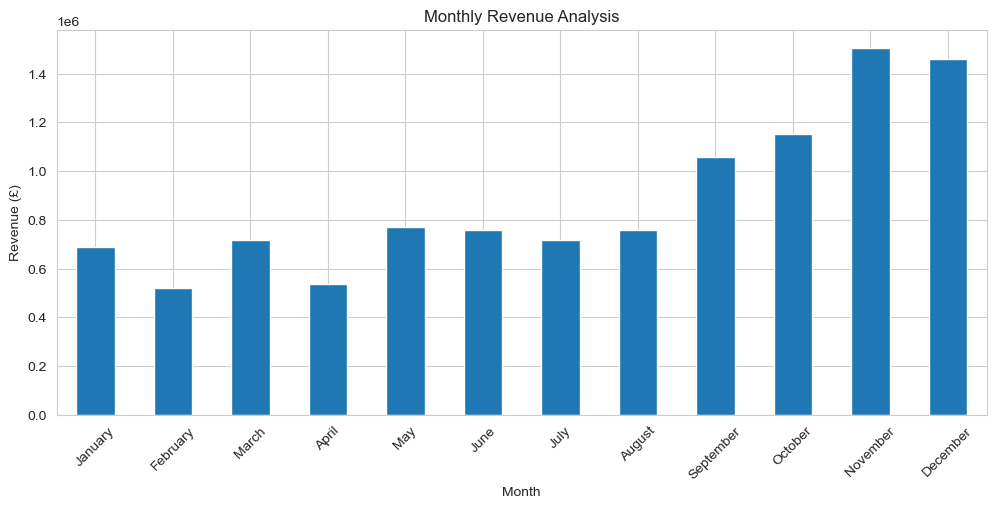

In [266]:
monthly_sales = (
    sales_df.groupby('MonthName')['Revenue']
    .sum()
)

month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

monthly_sales = monthly_sales.reindex(month_order)

plt.figure(figsize=(12,5))
monthly_sales.plot(kind='bar')

plt.title('Monthly Revenue Analysis')
plt.xlabel('Month')
plt.ylabel('Revenue (£)')
plt.xticks(rotation=45)
plt.show()

## Sales by weekday

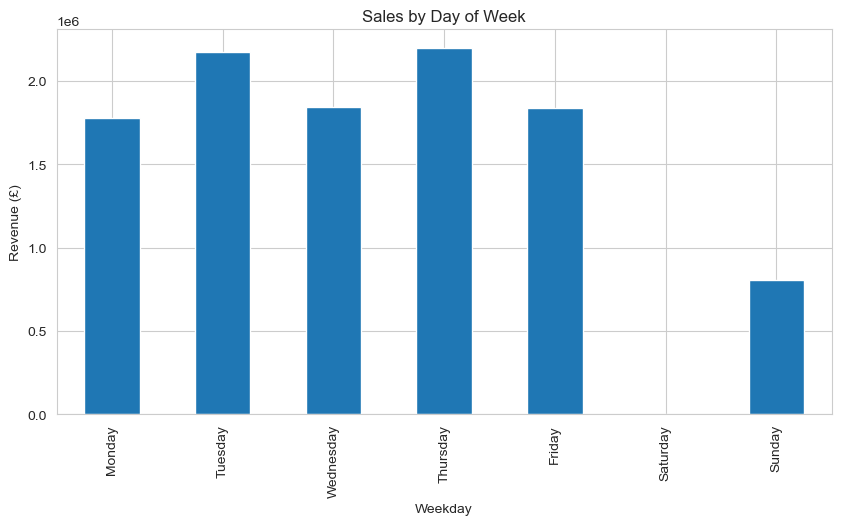

In [267]:
weekday_sales = sales_df.groupby('DayOfWeek')['Revenue'].sum()

weekday_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

weekday_sales = weekday_sales.reindex(weekday_order)

plt.figure(figsize=(10,5))
weekday_sales.plot(kind='bar')

plt.title('Sales by Day of Week')
plt.xlabel('Weekday')
plt.ylabel('Revenue (£)')
plt.show()

## Top 10 countries by revenue

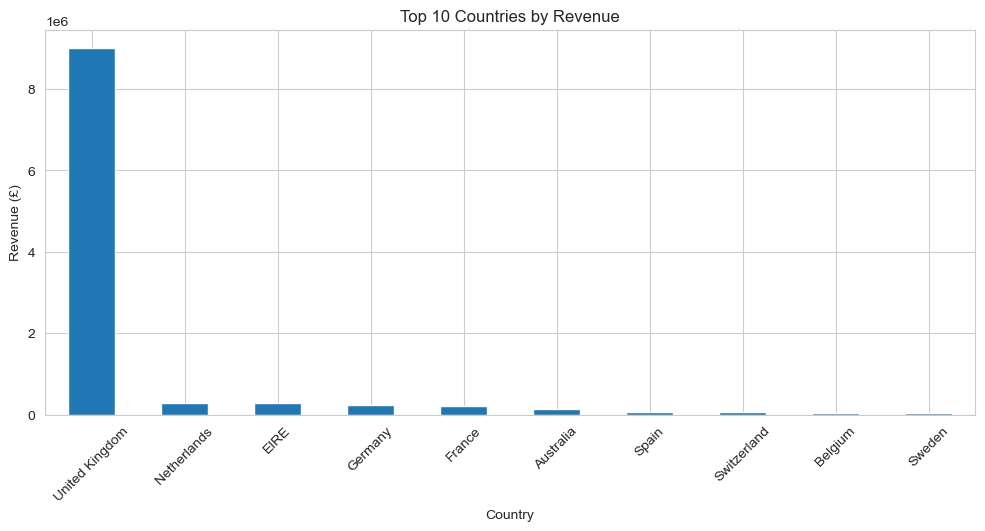

In [268]:
country_sales = (
    sales_df.groupby('Country')['Revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12,5))
country_sales.plot(kind='bar')

plt.title('Top 10 Countries by Revenue')
plt.ylabel('Revenue (£)')
plt.xticks(rotation=45)
plt.show()

## Monthly revenue by year

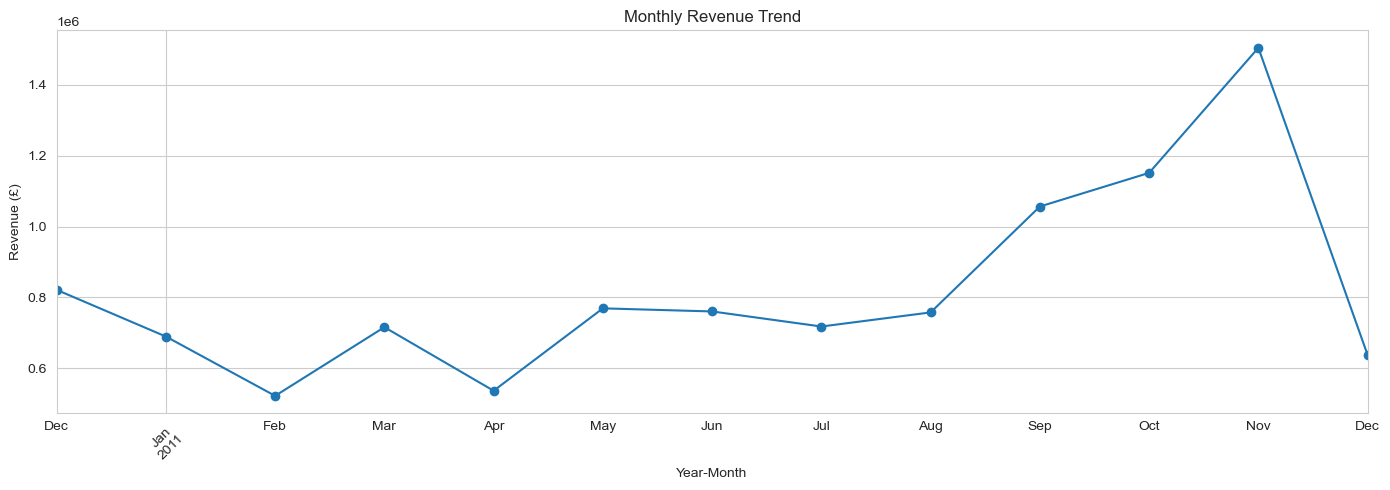

In [269]:
sales_df['YearMonth'] = sales_df['InvoiceDate'].dt.to_period('M')

monthly_trend = sales_df.groupby('YearMonth')['Revenue'].sum()

plt.figure(figsize=(14,5))
monthly_trend.plot(kind='line', marker='o')

plt.title('Monthly Revenue Trend')
plt.xlabel('Year-Month')
plt.ylabel('Revenue (£)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Stationarity and trend analysis

#### Plot daily sales

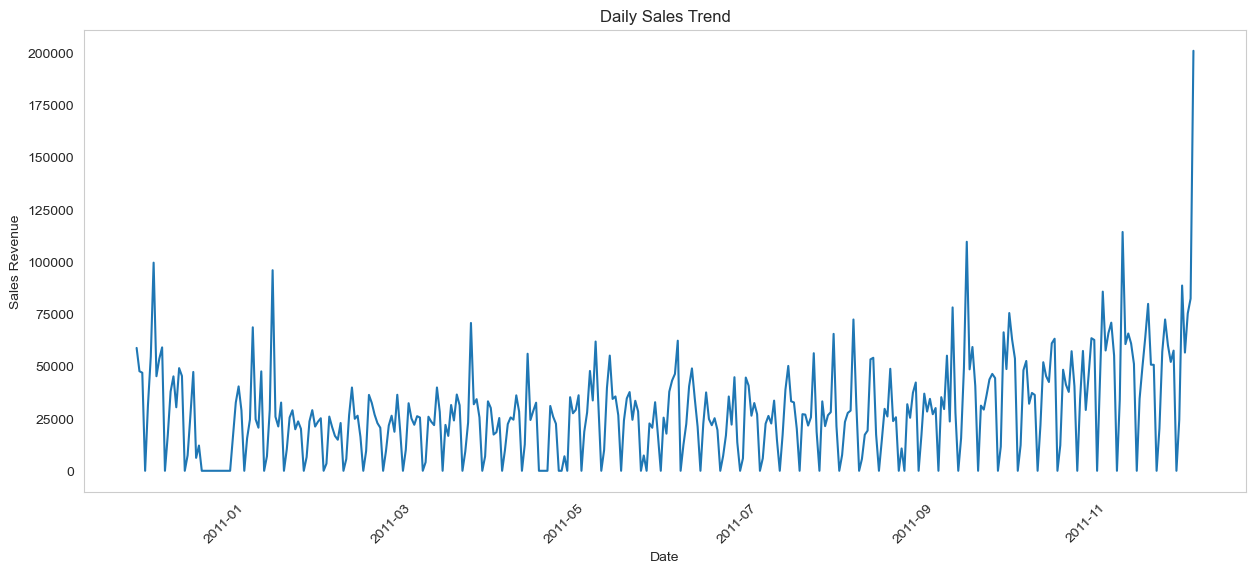

In [270]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

plt.plot(
    daily_sales['Date'],
    daily_sales['Sales']
)

plt.title('Daily Sales Trend')
plt.xlabel('Date')
plt.ylabel('Sales Revenue')

plt.xticks(rotation=45)
plt.grid()
plt.show()

# Check rolling mean and rolling standard deviation
Rolling mean helps us understand the trend.

Rolling standard deviation helps us understand fluctuations.

In [271]:
daily_sales['Rolling_Mean_7'] = (
    daily_sales['Sales']
    .rolling(window=7)
    .mean()
)

daily_sales['Rolling_Std_7'] = (
    daily_sales['Sales']
    .rolling(window=7)
    .std()
)

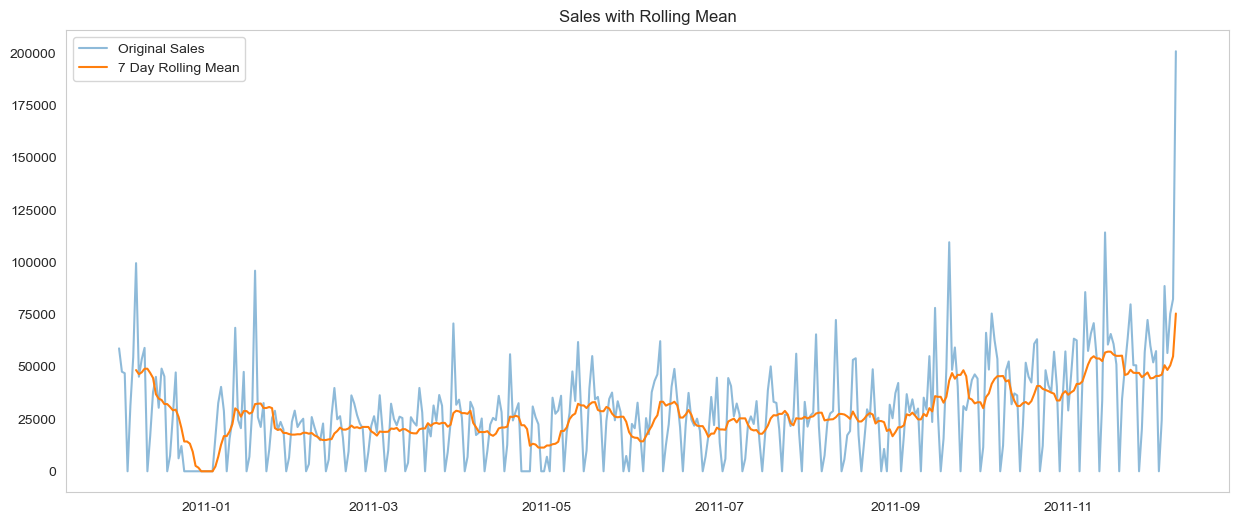

In [272]:
plt.figure(figsize=(15, 6))

plt.plot(
    daily_sales['Date'],
    daily_sales['Sales'],
    label='Original Sales',
    alpha=0.5
)

plt.plot(
    daily_sales['Date'],
    daily_sales['Rolling_Mean_7'],
    label='7 Day Rolling Mean'
)

plt.title('Sales with Rolling Mean')
plt.legend()
plt.grid()
plt.show()

### Rolling Mean and Rolling Standard Deviation

**1. Rolling Mean (7 Days):**

Rolling Mean calculates the average sales over the previous 7 days. It helps smooth daily fluctuations and identify the overall sales trend, such as increasing or decreasing sales.

**2. Rolling Standard Deviation (7 Days):**

Rolling Standard Deviation measures the variation in daily sales over the previous 7 days. It helps identify sales volatility and understand whether sales are stable or fluctuating significantly.

**3. Purpose:**

- Rolling Mean helps identify sales trends.
- Rolling Standard Deviation helps measure sales fluctuations.
- Both features help understand historical sales patterns.
- These features can be used in machine learning models to improve sales forecasting.

**Conclusion:**

Rolling Mean and Rolling Standard Deviation are useful time-series analysis techniques. Rolling Mean identifies the general sales direction, while Rolling Standard Deviation measures sales variability. Both provide valuable insights for understanding sales behaviour and building forecasting models.

#### Perform ADF test

In [273]:
from statsmodels.tsa.stattools import adfuller

result = adfuller(daily_sales['Sales'])

print("ADF Statistic:", result[0])
print("P-value:", result[1])

if result[1] <= 0.05:
    print("Data is Stationary")
else:
    print("Data is Non-Stationary")

ADF Statistic: -0.6416907692413907
P-value: 0.8612806698946143
Data is Non-Stationary


## Analyze returns

In [274]:
returns = df[df['Quantity'] < 0]

print("Total return transactions:", len(returns))
print("Total returned units:", abs(returns['Quantity'].sum()))
print("Return value (£):", abs(returns['Revenue'].sum()))

Total return transactions: 10587
Total returned units: 482517
Return value (£): 893979.73


# Feature Engineering

In [275]:
# Create date features
daily_sales['Day'] = daily_sales['Date'].dt.day

daily_sales['Month'] = daily_sales['Date'].dt.month

daily_sales['Year'] = daily_sales['Date'].dt.year

daily_sales['DayOfWeek'] = daily_sales['Date'].dt.dayofweek

daily_sales['WeekOfYear'] = (
    daily_sales['Date'].dt.isocalendar().week.astype(int)
)

In [276]:
# Create lag features
daily_sales['Lag_1'] = daily_sales['Sales'].shift(1)

daily_sales['Lag_7'] = daily_sales['Sales'].shift(7)

daily_sales['Lag_14'] = daily_sales['Sales'].shift(14)

daily_sales['Lag_28'] = daily_sales['Sales'].shift(28)

In [277]:
daily_sales['MA_7'] = (
    daily_sales['Sales']
    .shift(1)
    .rolling(window=7)
    .mean()
)

daily_sales['MA_14'] = (
    daily_sales['Sales']
    .shift(1)
    .rolling(window=14)
    .mean()
)

daily_sales['MA_30'] = (
    daily_sales['Sales']
    .shift(1)
    .rolling(window=30)
    .mean()
)

In [278]:
daily_sales = daily_sales.dropna().reset_index(drop=True)

In [279]:
daily_sales.head()

,Date,Sales,Rolling_Mean_7,Rolling_Std_7,Day,Month,Year,DayOfWeek,WeekOfYear,Lag_1,Lag_7,Lag_14,Lag_28,MA_7,MA_14,MA_30
0,2010-12-31,0.00,0.000000,0.000000,31,12,2010,4,52,0.0,0.0,45338.13,46898.63,0.0,10361.900000,27381.757667
1,2011-01-01,0.00,0.000000,0.000000,1,1,2011,5,52,0.0,0.0,0.00,0.00,0.0,7123.462143,25422.531333
2,2011-01-02,0.00,0.000000,0.000000,2,1,2011,6,52,0.0,0.0,7410.47,31364.63,0.0,7123.462143,23834.884000
3,2011-01-03,0.00,0.000000,0.000000,3,1,2011,0,1,0.0,0.0,26766.23,54624.15,0.0,6594.142857,22271.596333
4,2011-01-04,16005.73,2286.532857,6049.597305,4,1,2011,1,1,0.0,0.0,47279.89,99553.85,0.0,4682.269286,22271.596333


In [280]:
daily_sales.shape

(344, 16)

In [281]:
features = [
    'Day',
    'Month',
    'Year',
    'DayOfWeek',
    'WeekOfYear',
    'Lag_1',
    'Lag_7',
    'Lag_14',
    'Lag_28',
    'MA_7',
    'MA_14',
    'MA_30'
]

X = daily_sales[features]

In [282]:
y = daily_sales['Sales']

In [283]:
print("X Shape:", X.shape)
print("y Shape:", y.shape)

print("\nX Features:")
print(X.head())

print("\ny Target:")
print(y.head())

X Shape: (344, 12)
y Shape: (344,)

X Features:
   Day  Month  Year  DayOfWeek  WeekOfYear  Lag_1  Lag_7    Lag_14    Lag_28  \
0   31     12  2010          4          52    0.0    0.0  45338.13  46898.63   
1    1      1  2011          5          52    0.0    0.0      0.00      0.00   
2    2      1  2011          6          52    0.0    0.0   7410.47  31364.63   
3    3      1  2011          0           1    0.0    0.0  26766.23  54624.15   
4    4      1  2011          1           1    0.0    0.0  47279.89  99553.85   

   MA_7         MA_14         MA_30  
0   0.0  10361.900000  27381.757667  
1   0.0   7123.462143  25422.531333  
2   0.0   7123.462143  23834.884000  
3   0.0   6594.142857  22271.596333  
4   0.0   4682.269286  22271.596333  

y Target:
0        0.00
1        0.00
2        0.00
3        0.00
4    16005.73
Name: Sales, dtype: float64


## Train-Test Split

In [284]:
split_index = int(len(X) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

In [285]:
print("X Train:", X_train.shape)
print("X Test:", X_test.shape)

print("y Train:", y_train.shape)
print("y Test:", y_test.shape)

X Train: (275, 12)
X Test: (69, 12)
y Train: (275,)
y Test: (69,)


In [286]:
print("Training Start:", daily_sales['Date'].iloc[0])

print("Training End:",
      daily_sales['Date'].iloc[split_index - 1])

print("Testing Start:",
      daily_sales['Date'].iloc[split_index])

print("Testing End:", daily_sales['Date'].iloc[-1])

Training Start: 2010-12-31 00:00:00
Training End: 2011-10-01 00:00:00
Testing Start: 2011-10-02 00:00:00
Testing End: 2011-12-09 00:00:00


# Task 3 Model building

In [287]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

In [288]:
# Decision Tree Regressor
from sklearn.tree import DecisionTreeRegressor

dt_model = DecisionTreeRegressor(random_state=42)

dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)

In [289]:
# Rf
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

In [290]:
# Gboost
from sklearn.ensemble import GradientBoostingRegressor
gb_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

gb_model.fit(X_train, y_train)

gb_pred = gb_model.predict(X_test)

In [291]:
models = {
    'Decision Tree': dt_pred,
    'Random Forest': rf_pred,
    'Gradient Boosting': gb_pred
}

results = []

for name, pred in models.items():

    mae = mean_absolute_error(y_test, pred)

    rmse = np.sqrt(mean_squared_error(y_test, pred))

    r2 = r2_score(y_test, pred)

    results.append({
        'Model': name,
        'MAE': mae,
        'RMSE': rmse,
        'R2 Score': r2
    })

results_df = pd.DataFrame(results)

results_df

,Model,MAE,RMSE,R2 Score
0,Decision Tree,15929.862174,26249.820585,0.294792
1,Random Forest,12547.464283,23080.086849,0.454821
2,Gradient Boosting,14145.500447,24443.561970,0.388504


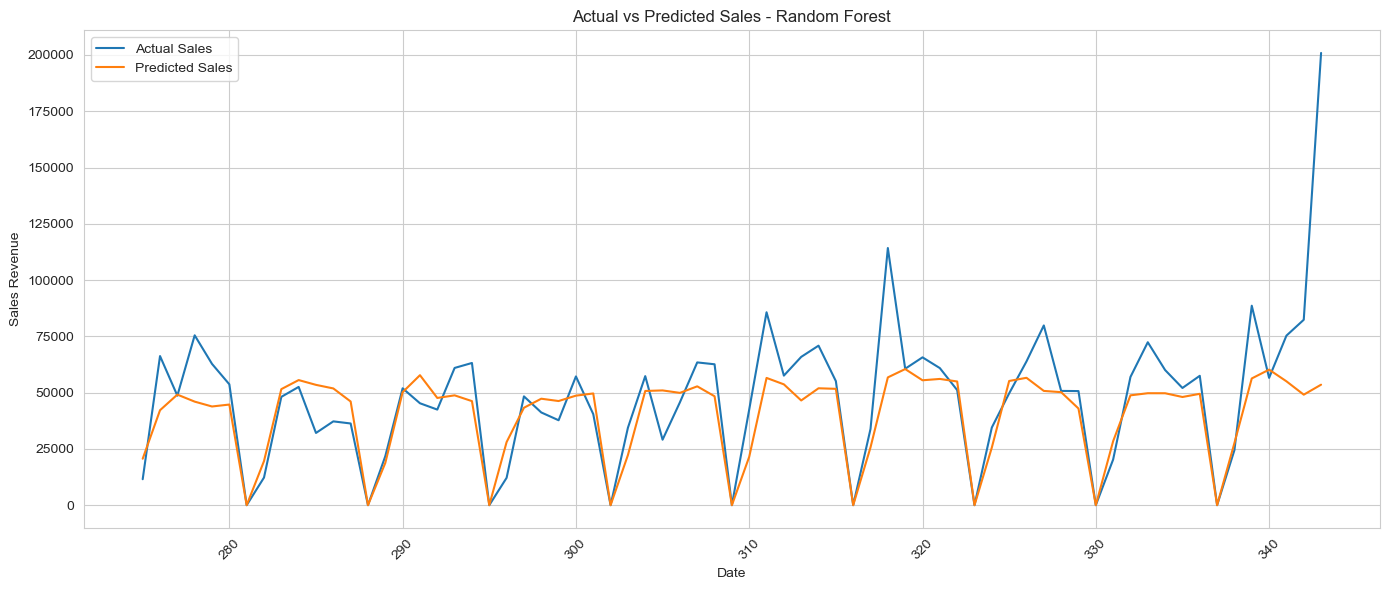

In [292]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14,6))

plt.plot(
    y_test.index,
    y_test.values,
    label='Actual Sales'
)

plt.plot(
    y_test.index,
    rf_pred,
    label='Predicted Sales'
)

plt.title('Actual vs Predicted Sales - Random Forest')
plt.xlabel('Date')
plt.ylabel('Sales Revenue')

plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [293]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Time-series cross-validation
tscv = TimeSeriesSplit(n_splits=5)

# Hyperparameter options
param_dist = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [None, 5, 10, 15, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 0.7, 1.0]
}

# Create Random Forest model
rf = RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)

# Hyperparameter tuning
random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_dist,
    n_iter=20,
    cv=tscv,
    scoring='neg_mean_absolute_error',
    random_state=42,
    n_jobs=-1
)

# Train on training data
random_search.fit(X_train, y_train)

# Best model
best_rf = random_search.best_estimator_

print("Best Parameters:", random_search.best_params_)
print("Best CV MAE:", -random_search.best_score_)

Best Parameters: {'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 4, 'max_features': 0.7, 'max_depth': 20}
Best CV MAE: 8007.138581392077


In [294]:
from sklearn.ensemble import RandomForestRegressor

final_rf = RandomForestRegressor(
    n_estimators=300,
    min_samples_split=2,
    min_samples_leaf=4,
    max_features=0.7,
    max_depth=20,
    random_state=42,
    n_jobs=-1
)

# Train on all available training data
final_rf.fit(X_train, y_train)

RandomForestRegressor(max_depth=20, max_features=0.7, min_samples_leaf=4,
                      n_estimators=300, n_jobs=-1, random_state=42)

In [295]:
y_pred = final_rf.predict(X_test)

In [296]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

r2 = r2_score(y_test, y_pred)

print("Random Forest Evaluation")
print("------------------------")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))
print("R2 Percentage:", round(r2 * 100, 2), "%")

Random Forest Evaluation
------------------------
MAE: 13244.86
RMSE: 23701.47
R2 Score: 0.4251
R2 Percentage: 42.51 %


In [298]:
# Convert InvoiceDate to datetime
sales_df['InvoiceDate'] = pd.to_datetime(sales_df['InvoiceDate'])

# Extract date only
sales_df['Date'] = sales_df['InvoiceDate'].dt.date

# Aggregate revenue by date
daily_sales = (
    sales_df.groupby('Date')['Revenue']
    .sum()
    .reset_index()
)

# Rename Revenue to Sales
daily_sales.rename(columns={'Revenue': 'Sales'}, inplace=True)

# Convert Date to datetime
daily_sales['Date'] = pd.to_datetime(daily_sales['Date'])

# Sort by date
daily_sales = daily_sales.sort_values('Date').reset_index(drop=True)

print(daily_sales.head())
print("Shape:", daily_sales.shape)

        Date     Sales
0 2010-12-01  58776.79
1 2010-12-02  47629.42
2 2010-12-03  46898.63
3 2010-12-05  31364.63
4 2010-12-06  54624.15
Shape: (305, 2)


In [299]:
print("First Date:", daily_sales['Date'].min())
print("Last Date:", daily_sales['Date'].max())

print("Total Days:", len(daily_sales))

print(daily_sales.describe())

First Date: 2010-12-01 00:00:00
Last Date: 2011-12-09 00:00:00
Total Days: 305
                                Date          Sales
count                            305     305.000000
mean   2011-06-10 20:03:56.065573888   34892.166570
min              2010-12-01 00:00:00    3439.670000
25%              2011-03-10 00:00:00   22345.930000
50%              2011-06-14 00:00:00   29526.290000
75%              2011-09-12 00:00:00   45277.920000
max              2011-12-09 00:00:00  200900.980000
std                              NaN   21098.282521


In [300]:
sales_history = (
    daily_sales
    .set_index('Date')['Sales']
    .asfreq('D')
    .fillna(0)
)

print(sales_history.tail())

Date
2011-12-05     88620.84
2011-12-06     56558.83
2011-12-07     75315.55
2011-12-08     82371.55
2011-12-09    200900.98
Freq: D, Name: Sales, dtype: float64


In [ ]:
final_rf.fit(X, y)

In [ ]:
history = sales_history.copy()

In [301]:
print("Daily sales records:", len(daily_sales))
print("Feature records:", len(X))

print("Daily sales last date:", daily_sales['Date'].max())
print("Feature dataset date range:")
print(X[['Day', 'Month', 'Year']].tail())

Daily sales records: 305
Feature records: 344
Daily sales last date: 2011-12-09 00:00:00
Feature dataset date range:
     Day  Month  Year
339    5     12  2011
340    6     12  2011
341    7     12  2011
342    8     12  2011
343    9     12  2011


In [302]:
print("Daily sales date range:")
print(daily_sales['Date'].min(), daily_sales['Date'].max())

print("Number of calendar days:",
      (daily_sales['Date'].max() - daily_sales['Date'].min()).days + 1)

print("Unique dates:", daily_sales['Date'].nunique())

Daily sales date range:
2010-12-01 00:00:00 2011-12-09 00:00:00
Number of calendar days: 374
Unique dates: 305


In [303]:
print("X shape:", X.shape)
print("y shape:", y.shape)

print("Target total:", y.sum())
print("Target mean:", y.mean())

X shape: (344, 12)
y shape: (344,)
Target total: 9820658.074000001
Target mean: 28548.424633720933


In [304]:
all_dates = pd.date_range(
    start=daily_sales['Date'].min(),
    end=daily_sales['Date'].max(),
    freq='D'
)

missing_dates = all_dates.difference(daily_sales['Date'])

print("Missing dates:", len(missing_dates))
print(missing_dates[:20])

Missing dates: 69
DatetimeIndex(['2010-12-04', '2010-12-11', '2010-12-18', '2010-12-24',
               '2010-12-25', '2010-12-26', '2010-12-27', '2010-12-28',
               '2010-12-29', '2010-12-30', '2010-12-31', '2011-01-01',
               '2011-01-02', '2011-01-03', '2011-01-08', '2011-01-15',
               '2011-01-22', '2011-01-29', '2011-02-05', '2011-02-12'],
              dtype='datetime64[ns]', freq=None)


In [305]:
daily_sales_full = (
    daily_sales
    .set_index('Date')['Sales']
    .reindex(all_dates, fill_value=0)
)

daily_sales_full.index.name = 'Date'

print("Continuous daily records:", len(daily_sales_full))

Continuous daily records: 374


In [306]:
feature_df = daily_sales_full.reset_index()

# Calendar features
feature_df['Day'] = feature_df['Date'].dt.day
feature_df['Month'] = feature_df['Date'].dt.month
feature_df['Year'] = feature_df['Date'].dt.year
feature_df['DayOfWeek'] = feature_df['Date'].dt.dayofweek
feature_df['WeekOfYear'] = feature_df['Date'].dt.isocalendar().week.astype(int)

# Lag features
feature_df['Lag_1'] = feature_df['Sales'].shift(1)
feature_df['Lag_7'] = feature_df['Sales'].shift(7)
feature_df['Lag_14'] = feature_df['Sales'].shift(14)
feature_df['Lag_28'] = feature_df['Sales'].shift(28)

# Moving averages (previous days only)
feature_df['MA_7'] = feature_df['Sales'].shift(1).rolling(7).mean()
feature_df['MA_14'] = feature_df['Sales'].shift(1).rolling(14).mean()
feature_df['MA_30'] = feature_df['Sales'].shift(1).rolling(30).mean()

# Remove rows with missing lag/rolling values
feature_df = feature_df.dropna().reset_index(drop=True)

# Create X and y
features = [
    'Day', 'Month', 'Year', 'DayOfWeek', 'WeekOfYear',
    'Lag_1', 'Lag_7', 'Lag_14', 'Lag_28',
    'MA_7', 'MA_14', 'MA_30'
]

X = feature_df[features]
y = feature_df['Sales']

print("X Shape:", X.shape)
print("y Shape:", y.shape)

print("First Date:", feature_df['Date'].min())
print("Last Date:", feature_df['Date'].max())

X Shape: (344, 12)
y Shape: (344,)
First Date: 2010-12-31 00:00:00
Last Date: 2011-12-09 00:00:00


In [307]:
final_rf.fit(X, y)

print("Final Random Forest model trained successfully!")

Final Random Forest model trained successfully!


In [308]:
import pandas as pd
import numpy as np

# Historical sales
history = daily_sales_full.copy()

# Future dates
future_dates = pd.date_range(
    start=history.index.max() + pd.Timedelta(days=1),
    periods=60,
    freq='D'
)

forecast_results = []

for date in future_dates:

    # Calendar features
    future_features = {
        'Day': date.day,
        'Month': date.month,
        'Year': date.year,
        'DayOfWeek': date.dayofweek,
        'WeekOfYear': date.isocalendar().week,

        # Lag features
        'Lag_1': history.iloc[-1],
        'Lag_7': history.iloc[-7],
        'Lag_14': history.iloc[-14],
        'Lag_28': history.iloc[-28],

        # Moving averages
        'MA_7': history.tail(7).mean(),
        'MA_14': history.tail(14).mean(),
        'MA_30': history.tail(30).mean()
    }

    # Convert into DataFrame
    future_X = pd.DataFrame([future_features])

    # Maintain training feature order
    future_X = future_X[X.columns]

    # Predict sales
    predicted_sales = final_rf.predict(future_X)[0]

    # Prevent negative revenue predictions
    predicted_sales = max(0, predicted_sales)

    # Store forecast
    forecast_results.append({
        'Date': date,
        'Predicted_Sales': predicted_sales
    })

    # Update history
    history.loc[date] = predicted_sales

# Create forecast DataFrame
forecast_df = pd.DataFrame(forecast_results)

print(forecast_df.head(10))
print("\nForecast Shape:", forecast_df.shape)

        Date  Predicted_Sales
0 2011-12-10      1275.948631
1 2011-12-11     34022.654041
2 2011-12-12     85283.760737
3 2011-12-13     85190.124980
4 2011-12-14     84988.323797
5 2011-12-15     85320.444964
6 2011-12-16     84333.760221
7 2011-12-17      1275.948631
8 2011-12-18     35557.919862
9 2011-12-19     81278.828733

Forecast Shape: (60, 2)


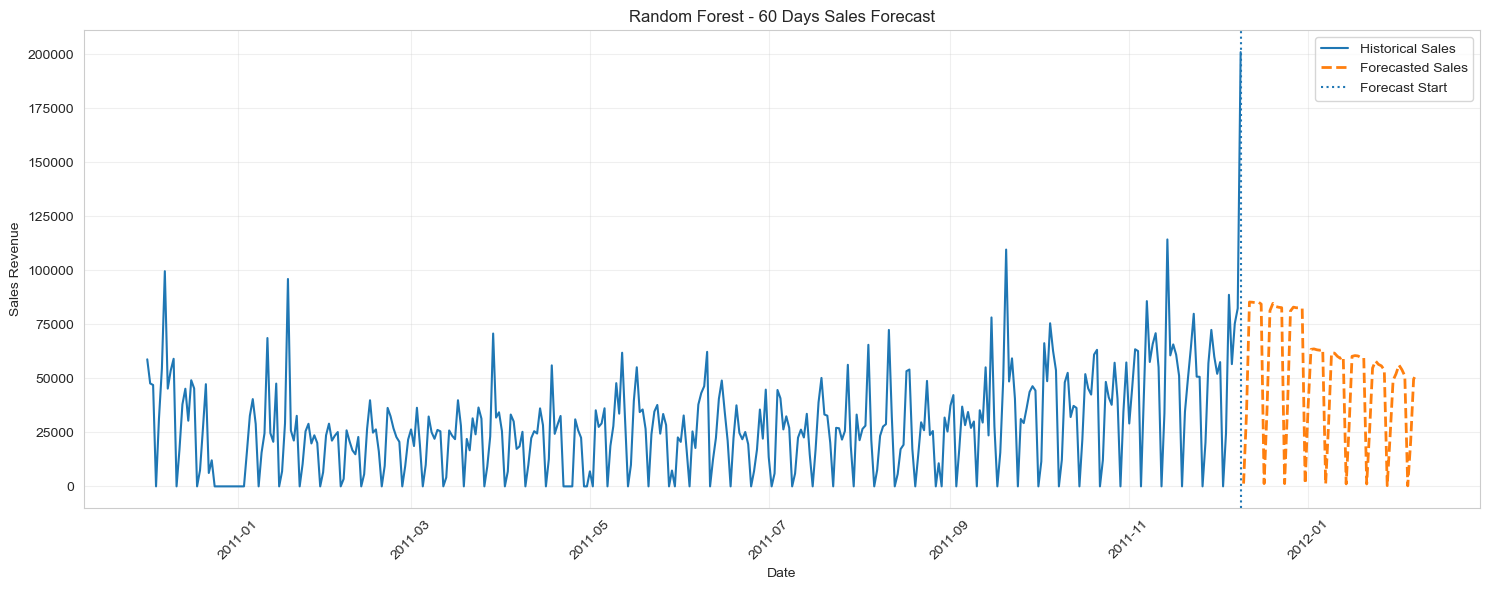

In [309]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

plt.plot(
    daily_sales_full.index,
    daily_sales_full.values,
    label='Historical Sales',
    linewidth=1.5
)

plt.plot(
    forecast_df['Date'],
    forecast_df['Predicted_Sales'],
    label='Forecasted Sales',
    linestyle='--',
    linewidth=2
)

plt.axvline(
    daily_sales_full.index.max(),
    linestyle=':',
    label='Forecast Start'
)

plt.title('Random Forest - 60 Days Sales Forecast')
plt.xlabel('Date')
plt.ylabel('Sales Revenue')
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [310]:
print("Total Forecasted Revenue:",
      round(forecast_df['Predicted_Sales'].sum(), 2))

print("Average Daily Sales:",
      round(forecast_df['Predicted_Sales'].mean(), 2))

print("Maximum Daily Sales:",
      round(forecast_df['Predicted_Sales'].max(), 2))

print("Minimum Daily Sales:",
      round(forecast_df['Predicted_Sales'].min(), 2))

Total Forecasted Revenue: 3093390.2
Average Daily Sales: 51556.5
Maximum Daily Sales: 85320.44
Minimum Daily Sales: 245.69


In [311]:
forecast_df.to_excel(
    'RandomForest_60_Days_Forecast.xlsx',
    index=False
)

In [312]:
import joblib
import os

os.makedirs('models', exist_ok=True)

joblib.dump(final_rf, 'models/final_rf.pkl')

print("Model saved successfully!")

Model saved successfully!


In [314]:
import os

# Create data folder if it doesn't exist
os.makedirs('data', exist_ok=True)

# Save daily sales dataset
daily_sales_full.rename('Sales').reset_index().to_csv(
    'data/daily_sales.csv',
    index=False
)

print("Daily sales dataset saved successfully!")

Daily sales dataset saved successfully!


In [315]:
import os

print("Current Working Directory:", os.getcwd())
print("Data folder exists:", os.path.exists('data'))
print("CSV file exists:", os.path.exists('data/daily_sales.csv'))

Current Working Directory: C:\Users\adiya\OneDrive\Desktop\data-Science-week2\notebook
Data folder exists: True
CSV file exists: True


# working with arima sarima

#### Extract Date and Sales

In [179]:
daily_sales['Date'] = pd.to_datetime(daily_sales['Date'])

daily_sales = daily_sales.sort_values('Date')

daily_sales = daily_sales.set_index('Date')

sales = daily_sales['Sales'].asfreq('D')

In [180]:
print("Start:", sales.index.min())
print("End:", sales.index.max())
print("Total days:", len(sales))
print("Missing values:", sales.isna().sum())

Start: 2010-12-31 00:00:00
End: 2011-12-09 00:00:00
Total days: 344
Missing values: 0


In [181]:
from statsmodels.tsa.stattools import adfuller

result = adfuller(sales)

print("ADF Statistic:", result[0])
print("p-value:", result[1])

if result[1] <= 0.05:
    print("Data is Stationary")
else:
    print("Data is Non-Stationary")

ADF Statistic: 0.3822496152053755
p-value: 0.9808188675537847
Data is Non-Stationary


In [182]:
sales_diff = sales.diff().dropna()

In [183]:
result = adfuller(sales_diff)

print("ADF Statistic:", result[0])
print("p-value:", result[1])

if result[1] <= 0.05:
    print("Data is Stationary")
else:
    print("Data is Non-Stationary")

ADF Statistic: -6.7959314546312655
p-value: 2.301067232616114e-09
Data is Stationary


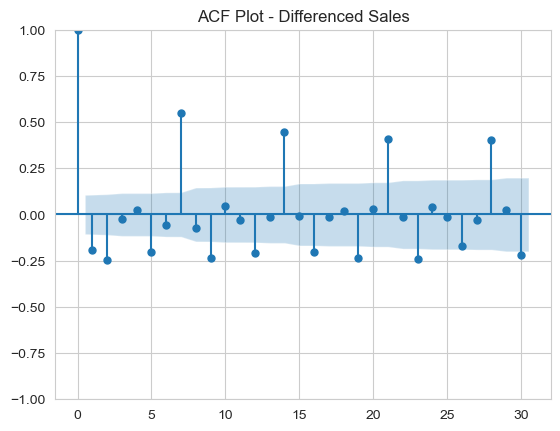

In [184]:
from statsmodels.graphics.tsaplots import plot_acf

plot_acf(sales_diff, lags=30)

plt.title('ACF Plot - Differenced Sales')
plt.show()

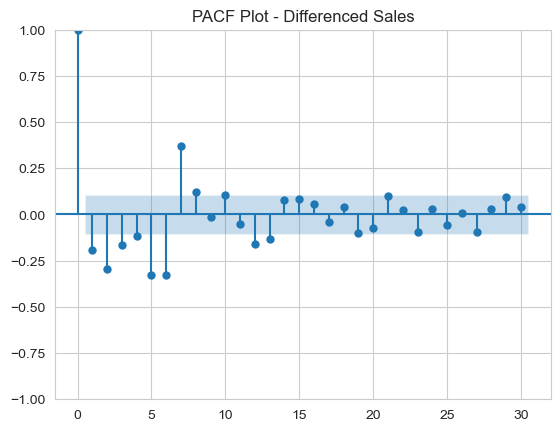

In [185]:
from statsmodels.graphics.tsaplots import plot_pacf

plot_pacf(sales_diff, lags=30, method='ywm')

plt.title('PACF Plot - Differenced Sales')
plt.show()

In [188]:
train = y_train
test = y_test

print("Train:", train.shape)
print("Test:", test.shape)

Train: (275,)
Test: (69,)


In [189]:
from statsmodels.tsa.arima.model import ARIMA

arima_model = ARIMA(
    train,
    order=(7, 1, 0)
)

arima_fit = arima_model.fit()

print(arima_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                  Sales   No. Observations:                  275
Model:                 ARIMA(7, 1, 0)   Log Likelihood               -3004.130
Date:                Mon, 16 Nov 2026   AIC                           6024.261
Time:                        01:00:46   BIC                           6053.166
Sample:                             0   HQIC                          6035.863
                                - 275                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.7280      0.063    -11.548      0.000      -0.852      -0.604
ar.L2         -0.7493      0.074    -10.141      0.000      -0.894      -0.605
ar.L3         -0.7304      0.076     -9.574      0.0

In [190]:
arima_pred = arima_fit.forecast(
    steps=len(test)
)

In [191]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

arima_mae = mean_absolute_error(test, arima_pred)

arima_rmse = np.sqrt(
    mean_squared_error(test, arima_pred)
)

arima_r2 = r2_score(test, arima_pred)

print("ARIMA MAE:", arima_mae)
print("ARIMA RMSE:", arima_rmse)
print("ARIMA R2 Score:", arima_r2)

ARIMA MAE: 24921.851247661085
ARIMA RMSE: 33737.450925789555
ARIMA R2 Score: -0.1649012831518566


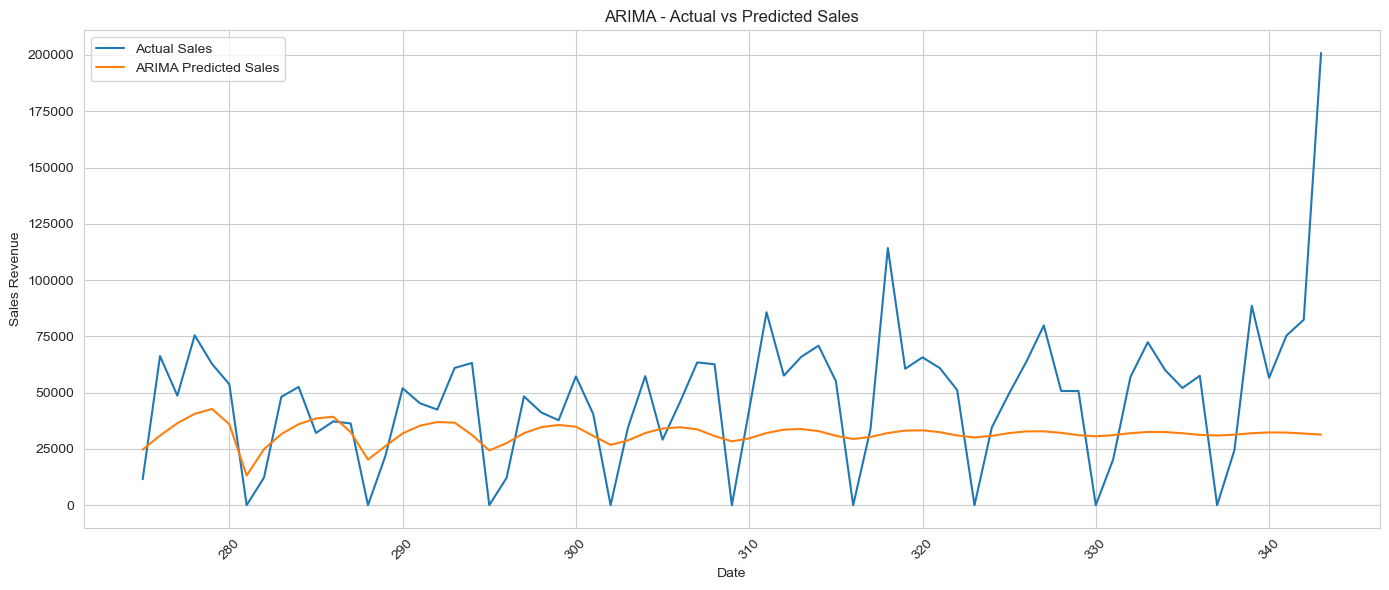

In [192]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(test.index, test.values, label='Actual Sales')

plt.plot(test.index, arima_pred, label='ARIMA Predicted Sales')

plt.title('ARIMA - Actual vs Predicted Sales')
plt.xlabel('Date')
plt.ylabel('Sales Revenue')

plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [193]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

sarima_model = SARIMAX(
    train,
    order=(1, 1, 1),
    seasonal_order=(1, 0, 1, 7)
)

sarima_fit = sarima_model.fit()

print(sarima_fit.summary())

C:\Users\adiya\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


                                     SARIMAX Results                                     
Dep. Variable:                             Sales   No. Observations:                  275
Model:             SARIMAX(1, 1, 1)x(1, 0, 1, 7)   Log Likelihood               -3004.588
Date:                           Mon, 16 Nov 2026   AIC                           6019.177
Time:                                   01:05:23   BIC                           6037.243
Sample:                                        0   HQIC                          6026.428
                                           - 275                                         
Covariance Type:                             opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.2228      0.123      1.812      0.070      -0.018       0.464
ma.L1         -0.9974      0.008   -124.291

In [194]:
sarima_pred = sarima_fit.forecast(
    steps=len(test)
)

In [195]:
sarima_mae = mean_absolute_error(test, sarima_pred)

sarima_rmse = np.sqrt(
    mean_squared_error(test, sarima_pred)
)

sarima_r2 = r2_score(test, sarima_pred)

print("SARIMA MAE:", sarima_mae)
print("SARIMA RMSE:", sarima_rmse)
print("SARIMA R2 Score:", sarima_r2)

SARIMA MAE: 23460.51888651478
SARIMA RMSE: 33801.612530746
SARIMA R2 Score: -0.16933629561945596


In [196]:
baseline_pred = test.shift(1)

baseline_pred.iloc[0] = train.iloc[-1]

In [197]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

baseline_mae = mean_absolute_error(test, baseline_pred)

baseline_rmse = np.sqrt(
    mean_squared_error(test, baseline_pred)
)

baseline_r2 = r2_score(test, baseline_pred)

print("Baseline MAE:", baseline_mae)
print("Baseline RMSE:", baseline_rmse)
print("Baseline R2 Score:", baseline_r2)

Baseline MAE: 25834.885217391304
Baseline RMSE: 33883.15877052907
Baseline R2 Score: -0.17498513853147601


In [198]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Time-series cross-validation
tscv = TimeSeriesSplit(n_splits=5)

# Hyperparameter options
param_dist = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [None, 5, 10, 15, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 0.7, 1.0]
}

# Create Random Forest model
rf = RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)

# Hyperparameter tuning
random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_dist,
    n_iter=20,
    cv=tscv,
    scoring='neg_mean_absolute_error',
    random_state=42,
    n_jobs=-1
)

# Train on training data
random_search.fit(X_train, y_train)

# Best model
best_rf = random_search.best_estimator_

print("Best Parameters:", random_search.best_params_)
print("Best CV MAE:", -random_search.best_score_)

Best Parameters: {'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 4, 'max_features': 0.7, 'max_depth': 20}
Best CV MAE: 8007.138581392077


In [200]:
from sklearn.ensemble import RandomForestRegressor

final_rf = RandomForestRegressor(
    n_estimators=300,
    min_samples_split=2,
    min_samples_leaf=4,
    max_features=0.7,
    max_depth=20,
    random_state=42,
    n_jobs=-1
)

# Train on all available training data
final_rf.fit(X_train, y_train)

RandomForestRegressor(max_depth=20, max_features=0.7, min_samples_leaf=4,
                      n_estimators=300, n_jobs=-1, random_state=42)

In [212]:
y_pred = final_rf.predict(X_test)

In [213]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

r2 = r2_score(y_test, y_pred)

print("Random Forest Evaluation")
print("------------------------")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))
print("R2 Percentage:", round(r2 * 100, 2), "%")

Random Forest Evaluation
------------------------
MAE: 13244.86
RMSE: 23701.47
R2 Score: 0.4251
R2 Percentage: 42.51 %


In [214]:

comparison = pd.DataFrame({
    'Actual Sales': y_test.values,
    'Predicted Sales': y_pred
})

comparison['Error'] = (
    comparison['Actual Sales'] - comparison['Predicted Sales']
)

comparison.head(10)

,Actual Sales,Predicted Sales,Error
0,11531.56,22954.231017,-11422.671017
1,66243.94,42945.686187,23298.253813
2,48652.54,44652.604551,3999.935449
3,75460.77,45856.939199,29603.830801
4,62761.92,45476.085207,17285.834793
5,53692.50,44775.891967,8916.608033
6,0.00,44.895981,-44.895981
7,12273.10,20293.085101,-8019.985101
8,48121.66,54170.559913,-6048.899913
9,52537.31,46971.514830,5565.795170


In [215]:
features = [
    'Day', 'Month', 'Year', 'DayOfWeek', 'WeekOfYear',
    'Lag_1', 'Lag_7', 'Lag_14', 'Lag_28',
    'MA_7', 'MA_14', 'MA_30'
]

In [216]:
final_rf.fit(X, y)

RandomForestRegressor(max_depth=20, max_features=0.7, min_samples_leaf=4,
                      n_estimators=300, n_jobs=-1, random_state=42)

In [217]:
import pandas as pd
import numpy as np

# Ensure Date is correct
daily_sales['Date'] = pd.to_datetime(daily_sales['Date'])

daily_sales = daily_sales.sort_values('Date').reset_index(drop=True)

# Historical sales
sales_history = daily_sales['Sales'].tolist()

# Last date
last_date = daily_sales['Date'].max()

# Future dates
future_dates = pd.date_range(
    start=last_date + pd.Timedelta(days=1),
    periods=60,
    freq='D'
)

predictions = []

for date in future_dates:

    future_features = {
        'Day': date.day,
        'Month': date.month,
        'Year': date.year,
        'DayOfWeek': date.dayofweek,
        'WeekOfYear': date.isocalendar().week,

        'Lag_1': sales_history[-1],
        'Lag_7': sales_history[-7],
        'Lag_14': sales_history[-14],
        'Lag_28': sales_history[-28],

        'MA_7': np.mean(sales_history[-7:]),
        'MA_14': np.mean(sales_history[-14:]),
        'MA_30': np.mean(sales_history[-30:])
    }

    future_X = pd.DataFrame(
        [future_features],
        columns=features
    )

    predicted_sales = final_rf.predict(future_X)[0]

    predictions.append(predicted_sales)

    sales_history.append(predicted_sales)

In [219]:
forecast_df = pd.DataFrame({
    'Date': future_dates,
    'Predicted_Sales': predictions
})

forecast_df.head(10)

,Date,Predicted_Sales
0,1970-01-02 00:00:00.000000343,24621.765122
1,1970-01-03 00:00:00.000000343,24105.364976
2,1970-01-04 00:00:00.000000343,47438.268935
3,1970-01-05 00:00:00.000000343,63994.156279
4,1970-01-06 00:00:00.000000343,64163.125612
5,1970-01-07 00:00:00.000000343,64534.164053
6,1970-01-08 00:00:00.000000343,64015.950147
7,1970-01-09 00:00:00.000000343,34100.630714
8,1970-01-10 00:00:00.000000343,24960.479851
9,1970-01-11 00:00:00.000000343,40120.489318


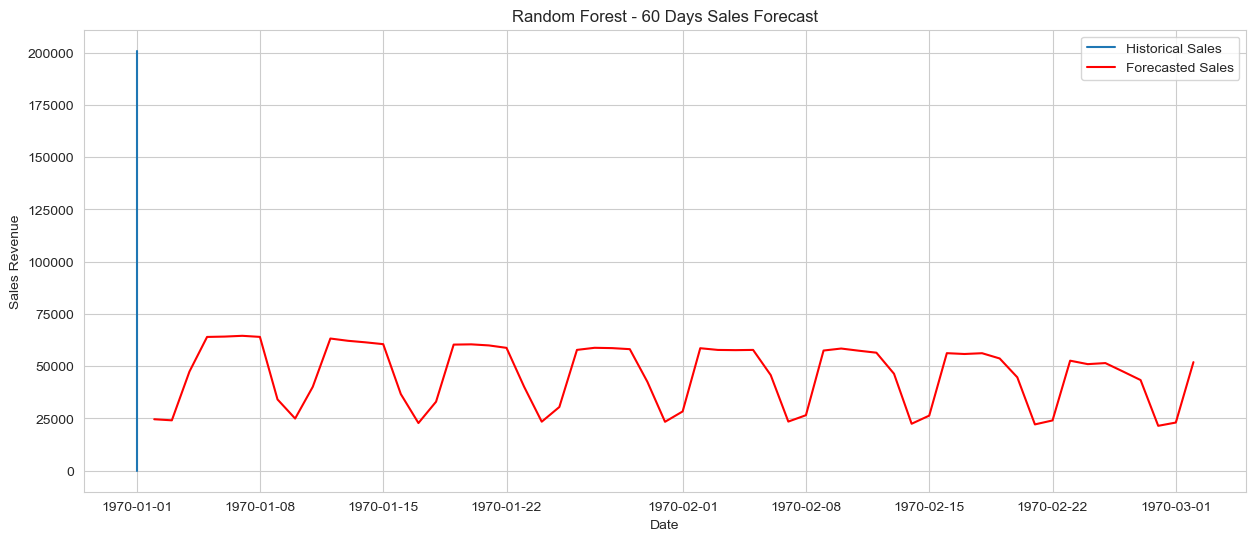

In [220]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

plt.plot(
    daily_sales['Date'],
    daily_sales['Sales'],
    label='Historical Sales'
)

plt.plot(
    forecast_df['Date'],
    forecast_df['Predicted_Sales'],
    color='red',
    label='Forecasted Sales'
)

plt.title('Random Forest - 60 Days Sales Forecast')
plt.xlabel('Date')
plt.ylabel('Sales Revenue')
plt.legend()
plt.grid(True)
plt.show()

In [221]:
print("Total 60 Days Forecast:",
      round(forecast_df['Predicted_Sales'].sum(), 2))

print("Average Daily Sales:",
      round(forecast_df['Predicted_Sales'].mean(), 2))

Total 60 Days Forecast: 2761004.07
Average Daily Sales: 46016.73


In [80]:
monthly_sales = (
    daily_sales
    .set_index('Date')
    .resample('MS')['DailySales']
    .sum()
    .reset_index()
)

monthly_sales.columns = ['Month', 'MonthlySales']

monthly_sales

,Month,MonthlySales
0,2010-12-01,821452.730
1,2011-01-01,689811.610
2,2011-02-01,522545.560
3,2011-03-01,716215.260
4,2011-04-01,536968.491
5,2011-05-01,769296.610
6,2011-06-01,760547.010
7,2011-07-01,718076.121
8,2011-08-01,757841.380
9,2011-09-01,1056435.192


### Visualize monthly revenue

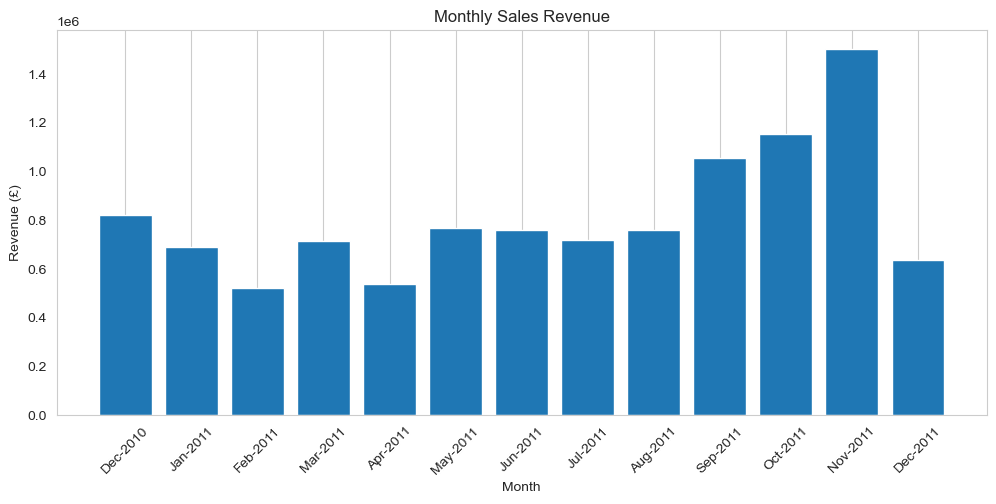

In [81]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.bar(
    monthly_sales['Month'].dt.strftime('%b-%Y'),
    monthly_sales['MonthlySales']
)

plt.title('Monthly Sales Revenue')
plt.xlabel('Month')
plt.ylabel('Revenue (£)')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()

In [82]:
print("Highest Sales Month:")
print(monthly_sales.loc[monthly_sales['MonthlySales'].idxmax()])

print("\nLowest Sales Month:")
print(monthly_sales.loc[monthly_sales['MonthlySales'].idxmin()])

Highest Sales Month:
Month           2011-11-01 00:00:00
MonthlySales             1503866.78
Name: 11, dtype: object

Lowest Sales Month:
Month           2011-02-01 00:00:00
MonthlySales              522545.56
Name: 2, dtype: object
